In [16]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import euclidean_distances
from sklearn_extra.cluster._k_medoids import KMedoids

from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

from scipy.spatial.distance import cdist, pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components

from scipy.cluster.hierarchy import linkage, fcluster

from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns



Adjusted Rand index compared to true class (iris species)
K-Medoids (AMPL) : ARI = 0.6765
K-Medoids (heuristic) : ARI = 0.7583
MST (heuristic) : ARI = 0.5638


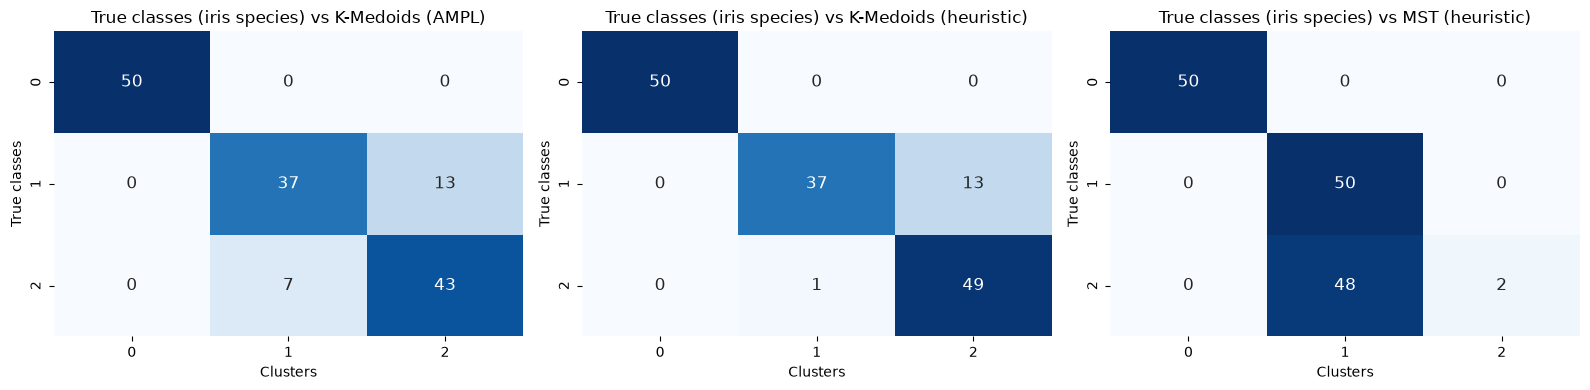

In [ ]:

iris = load_iris()
X = iris.data
y = iris.target
k = 3

# Results of the different methods
df_labels = pd.read_csv("iris_labels.txt", header=None)
ampl_labels_med = df_labels.iloc[:, 0].values
_, ampl_labels = np.unique(ampl_labels_med, return_inverse=True)

kmedoids = KMedoids(n_clusters=3, random_state=42)
kmedoids.fit(X)
labels_heur_kmed = kmedoids.labels_

mst_clustering = AgglomerativeClustering(n_clusters=3, linkage="single")
labels_heur_mst = mst_clustering.fit_predict(X)

methods = {
    "K-Medoids (AMPL)": ampl_labels,
    "K-Medoids (heuristic)": labels_heur_kmed,
    "MST (heuristic)": labels_heur_mst,
}

# ARI
print("Adjusted Rand index compared to true class (iris species)")
for name, labels in methods.items():
  ari = adjusted_rand_score(y, labels)
  print(f"{name} : ARI = {ari:.4f}")


# Re-aligning clusters to compare in the confusion matrix
def align_cluster_labels(y_true, y_pred):
  cm = confusion_matrix(y_true, y_pred)
  row_ind, col_ind = linear_sum_assignment(-cm)
  mapping = {col: row for row, col in zip(row_ind, col_ind)}
  return np.array([mapping.get(label, label) for label in y_pred])


# Display
fig, axes = plt.subplots(1, len(methods), figsize=(16, 4))

for ax, (name, labels) in zip(axes, methods.items()):
  # Re-aligning
  labels_aligned = align_cluster_labels(y, labels)
  cm = confusion_matrix(y, labels_aligned)

  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      cbar=False,
      ax=ax,
      annot_kws={"size": 12},
  )
  ax.set_title(f"True classes (iris species) vs {name}")
  ax.set_xlabel("Clusters")
  ax.set_ylabel("True classes")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [26]:
from scipy.sparse.csgraph import connected_components, minimum_spanning_tree
from scipy.spatial.distance import pdist, squareform
import scipy.sparse as sp


num_iterations = 20

print(
    f"Benchmark on {num_iterations} iterations"
)

# K-medoids (heuristic)
kmed_times = []
for i in range(num_iterations):
  start = time.perf_counter()
  kmed = KMedoids(n_clusters=3, random_state=42).fit(X)
  labels_heur_kmed = kmed.labels_
  end = time.perf_counter()
  kmed_times.append(end - start)


# MST (heuristic with scipy)
mst_times = []
for _ in range(num_iterations):
  start = time.perf_counter()
  dist_matrix = squareform(pdist(X))
  mst_matrix = minimum_spanning_tree(dist_matrix)
  mst_coo = mst_matrix.tocoo()
  edges = sorted(
      zip(mst_coo.row, mst_coo.col, mst_coo.data),
      key=lambda x: x[2],
      reverse=True,
  )
  edges_to_keep = edges[3 - 1 :]  # k-1 edges to cut with k=3
  row = [e[0] for e in edges_to_keep] + [e[1] for e in edges_to_keep]
  col = [e[1] for e in edges_to_keep] + [e[0] for e in edges_to_keep]
  data = [e[2] for e in edges_to_keep] + [e[2] for e in edges_to_keep]
  pruned_mst = sp.coo_matrix((data, (row, col)), shape=dist_matrix.shape).tocsr()
  _, labels_heur_mst = connected_components(
      pruned_mst, directed=False, return_labels=True
  )
  end = time.perf_counter()
  mst_times.append(end - start)
from sklearn.cluster import AgglomerativeClustering

# MST (heuristic with sklearn)
agg_mst_times = []
for _ in range(num_iterations):
  start = time.perf_counter()
  agg = AgglomerativeClustering(n_clusters=3, linkage="single")
  labels_agg = agg.fit_predict(X)
  end = time.perf_counter()
  agg_mst_times.append(end - start)

# Results
results = {
    "Method": [
        "K-Medoids (heuristic)",
        "MST (heuristic with scipy)",
        "MST (heuristic with sklearn)",
    ],
    "Average time (s)": [
        np.mean(kmed_times),
        np.mean(mst_times),
        np.mean(agg_mst_times),
    ],
    "Standard error (s)": [
        np.std(kmed_times),
        np.std(mst_times),
        np.std(agg_mst_times),
    ],
}

df_bench = pd.DataFrame(results)

print("\n")
print(df_bench.to_string(index=False))
df_bench.to_csv("time_comparison.csv", index=False)


Benchmark on 20 iterations


                      Method  Average time (s)  Standard error (s)
       K-Medoids (heuristic)          0.002242            0.000309
  MST (heuristic with scipy)          0.004809            0.002994
MST (heuristic with sklearn)          0.000846            0.000082
